# IND320 Project Work, Part 2

**Course:** IND320 Data to Decision  
**Student:** Sara Christine Gjerløw  

**GitHub repository:** https://github.com/SaraGjerlow/ind320-SaraGjerlow  
**Streamlit app:** https://ind320-saragjerlow.streamlit.app

This notebook replaces the CSV file from part 1 with a direct API connection to
NVE, retrieves cross-border power flow data from ENTSO-E, stores it in a local
Cassandra database through Spark, and loads the result into MongoDB, which is
what the Streamlit app reads from.

## 1. Imports

In [1]:
import os
import tomllib
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
from cassandra.cluster import Cluster
from entsoe import EntsoePandasClient
from pymongo.mongo_client import MongoClient
from pymongo.server_api import ServerApi
from pyspark.sql import SparkSession

## 2. Database connections

Both the MongoDB connection string and the ENTSO-E security token are read from
`.streamlit/secrets.toml`. That file is listed in `.gitignore`, so the
credentials never reach GitHub, and the Streamlit app reads the same file, which
means there is only one place to update them.

In [2]:
# Read both secrets from the one file that holds them.
with open(Path("../.streamlit/secrets.toml"), "rb") as f:
    secrets = tomllib.load(f)

mongo_uri = secrets["mongo"]["uri"]
entsoe_token = secrets["entsoe"]["token"]

# Verify the MongoDB connection before relying on it further down.
mongo_client = MongoClient(mongo_uri, server_api=ServerApi("1"))

try:
    mongo_client.admin.command("ping")
    print("Connected to MongoDB.")
except Exception as error:
    print(error)

# Confirm the token was loaded without printing it into the notebook.
print("ENTSO-E token loaded:", len(entsoe_token), "characters")

Connected to MongoDB.
ENTSO-E token loaded: 36 characters


## 3. Magasinstatistikk from the NVE API

Part 1 read a local CSV file. Here the same data is fetched directly from NVE's
API instead, so it is always current and no data file has to be stored in the
repository.

In [3]:
API_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

response = requests.get(API_URL)
response.raise_for_status()  # Raises a clear error if the request failed.

# The response is JSON with one object per measurement, which maps directly
# onto a DataFrame.
df = pd.DataFrame(response.json())

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (14922, 11)


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


## 4. Areas covered by the API

The rows are not one time series but several stacked on top of each other, one
per area. NVE publishes a separate endpoint listing the areas, which is used
here to find out what the area columns mean.

In [4]:
AREAS_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOmr%C3%A5der"

# The response is a list holding a single object, which groups the areas as
# land, elspot and vassdrag. [0] unwraps that object.
areas_raw = requests.get(AREAS_URL).json()[0]

# Flatten the three groups into one table so all areas can be seen together.
rows = []
for group_name, group in areas_raw.items():
    for area in group:
        area["group"] = group_name
        rows.append(area)

areas = pd.DataFrame(rows)
areas

,navn,navn_langt,beskrivelse,omrType,omrnr,group
0,Norge,Norge,Hele landet,NO,0,land
1,NO 1,Elspotområde 1,Sørøst-Norge. Omfatter østlige del av Østlande...,EL,1,elspot
2,NO 2,Elspotområde 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...,EL,2,elspot
3,NO 3,Elspotområde 3,Midt-Norge. Omfatter nordre og vestlige del av...,EL,3,elspot
4,NO 4,Elspotområde 4,Nord-Norge. Omfatter resten av Trøndelag og No...,EL,4,elspot
5,NO 5,Elspotområde 5,Vest-Norge. Omfatter midtre del av Vestland op...,EL,5,elspot
6,VASS1,Vassdragsområde 1,"Sørøst-Norge. Østlandet, Agder og deler av Rog...",VASS,1,vassdrag
7,VASS2,Vassdragsområde 2,Vest-Norge. Resten av Rogaland og Vestland.,VASS,2,vassdrag
8,VASS3,Vassdragsområde 3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl...",VASS,3,vassdrag
9,VASS4,Vassdragsområde 4,Nord-Norge. Resten av Nordland og nordover.,VASS,4,vassdrag


The API defines ten areas: Norway as a whole (NO 0), five electricity price
areas (EL 1 to 5) and four watercourse areas (VASS 1 to 4). The next cell checks
which of them are actually reported in the measurements, since an area can be
defined without being published as a separate series.

In [5]:
# Count the rows belonging to each area.
print(df.groupby(["omrType", "omrnr"]).size())

omrType  omrnr
EL       1        1658
         2        1658
         3        1658
         4        1658
         5        1658
NO       0        1658
VASS     1        1658
         2        1658
         3        1658
dtype: int64


Only nine areas occur, each with the same number of weekly observations. VASS 4
is defined by NVE but is not reported separately, which matters for the app:
building the area selector from the areas list alone would give the user a
choice that returns no data.

## 5. Plots from part 1, now from the API

The same preparation as in part 1: keep the national total so each column
becomes a single time series, sort by date, and translate the Norwegian headers
to English.

In [6]:
# Keep the national total only. NO is the single-area type covering the country.
national = df[df["omrType"] == "NO"].copy()

# Turn the date column into real dates, then sort the rows by date.
national["dato_Id"] = pd.to_datetime(national["dato_Id"])
national = national.sort_values("dato_Id")

# Keep the date and the five measurement columns. The others are area codes,
# week numbers that repeat the date, and a publication timestamp.
data = national[[
    "dato_Id",
    "fyllingsgrad",
    "kapasitet_TWh",
    "fylling_TWh",
    "fyllingsgrad_forrige_uke",
    "endring_fyllingsgrad",
]]

# Translate the Norwegian headers to English, with the unit in the name.
data = data.rename(columns={
    "dato_Id": "Date",
    "fyllingsgrad": "Fill level (fraction)",
    "kapasitet_TWh": "Capacity (TWh)",
    "fylling_TWh": "Stored energy (TWh)",
    "fyllingsgrad_forrige_uke": "Fill level previous week (fraction)",
    "endring_fyllingsgrad": "Change in fill level (fraction)",
})

# Use the date as the row index, so it becomes the x-axis in the plots.
data = data.set_index("Date")

print("Rows and columns:", data.shape)
print("First date:", data.index.min())
print("Last date:", data.index.max())
data.head()

Rows and columns: (1658, 5)
First date: 1995-01-08 00:00:00
Last date: 2026-10-11 00:00:00


,Fill level (fraction),Capacity (TWh),Stored energy (TWh),Fill level previous week (fraction),Change in fill level (fraction)
Date,,,,,
1995-01-08,0.607988,87.43758,53.161003,0.752631,-0.144643
1995-01-15,0.582088,87.43758,50.896374,0.607988,-0.025900
1995-01-22,0.562121,87.43758,49.150486,0.582088,-0.019967
1995-01-29,0.534222,87.43758,46.711033,0.562121,-0.027899
1995-02-05,0.506221,87.43758,44.262720,0.534222,-0.028001


### Each column separately

One figure per column, so every variable is shown on its own scale.

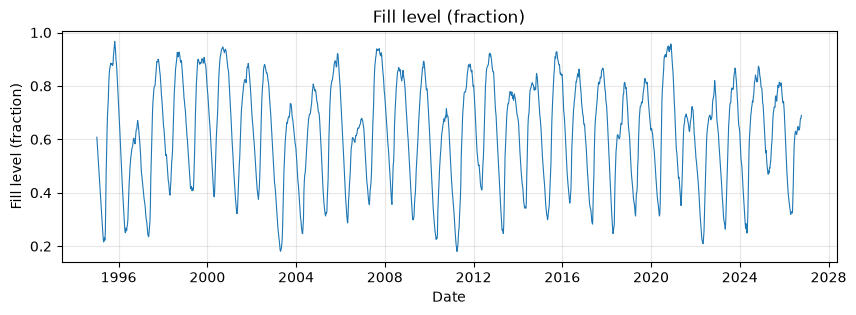

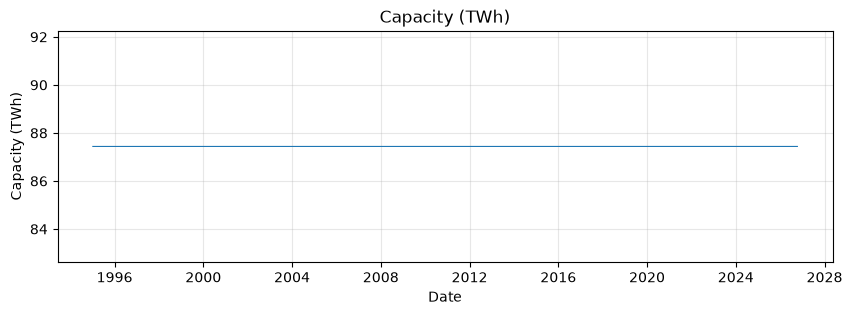

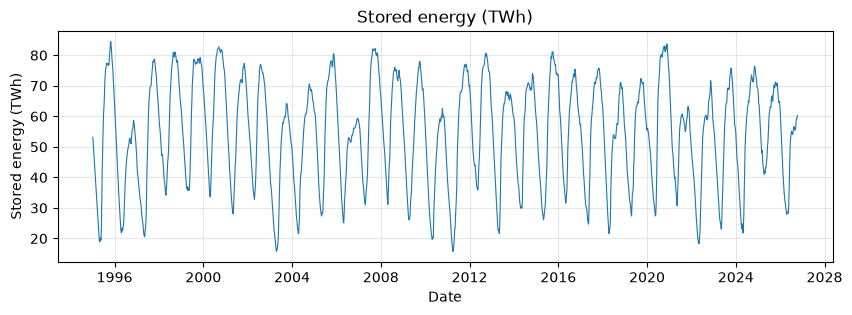

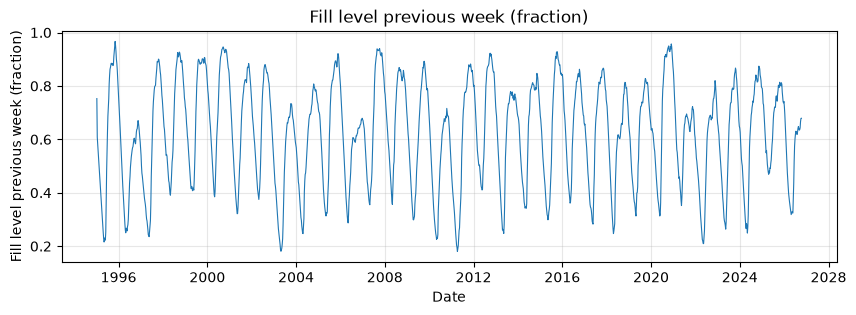

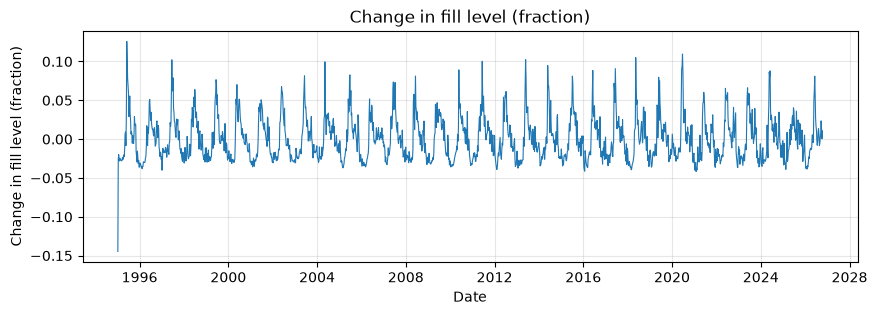

In [7]:
for column in data.columns:
    fig, ax = plt.subplots(figsize=(10, 3))
    ax.plot(data.index, data[column], linewidth=0.8)
    ax.set_title(column)
    ax.set_xlabel("Date")
    ax.set_ylabel(column)
    ax.grid(alpha=0.3)
    plt.show()

### All columns together

The columns use different units: two are energy in TWh, two are fractions
between 0 and 1, and one is a weekly change around zero. Drawn on one axis
without adjustment, the three small columns would be flat lines along the
bottom, so each column is rescaled to run from 0 to 1. The cost is that the
real values are no longer readable from the plot.

Capacity is the same value in every row, so it has no range to rescale by and
is left out.

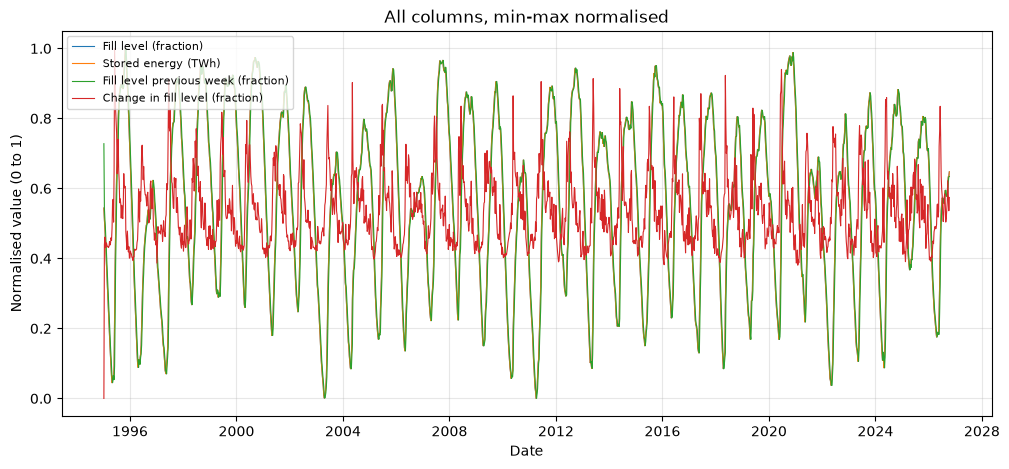

In [8]:
# The four columns to plot, capacity excluded.
columns_to_plot = [
    "Fill level (fraction)",
    "Stored energy (TWh)",
    "Fill level previous week (fraction)",
    "Change in fill level (fraction)",
]

fig, ax = plt.subplots(figsize=(12, 5))

for column in columns_to_plot:
    values = data[column]
    # Min-max normalisation: rescale the column so it runs from 0 to 1.
    normalised = (values - values.min()) / (values.max() - values.min())
    ax.plot(data.index, normalised, linewidth=0.8, label=column)

ax.set_title("All columns, min-max normalised")
ax.set_xlabel("Date")
ax.set_ylabel("Normalised value (0 to 1)")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="upper left")
plt.show()

## 6. ENTSO-E cross-border flows

ENTSO-E publishes the physical power flow across every border in Europe. The API
answers in XML, so the `entsoe-py` package is used to call it: it wraps the same
REST API and returns pandas objects instead.

Flow has a direction. A query from NO2 to a neighbour is power leaving Norway,
and the opposite query is power entering Norway, so each connection needs two
calls. The four connections below are the subsea interconnectors running from
bidding zone NO2 to other countries.

This cell takes about fifteen minutes, because each of the eight queries covers
two years and the API is slow.

In [9]:
entsoe_client = EntsoePandasClient(api_key=entsoe_token)

# The API requires timezone-aware timestamps.
end = pd.Timestamp.now(tz="Europe/Oslo").normalize()
start = end - pd.DateOffset(years=2)

# The four subsea interconnectors from bidding zone NO2.
CONNECTIONS = {
    "Skagerrak (DK1)": "DK_1",
    "NorNed (NL)": "NL",
    "NordLink (DE-LU)": "DE_LU",
    "North Sea Link (GB)": "GB",
}

NORWAY_ZONE = "NO_2"

rows = []

for name, neighbour in CONNECTIONS.items():
    # Export is power leaving Norway, import is power entering Norway.
    export = entsoe_client.query_crossborder_flows(NORWAY_ZONE, neighbour, start=start, end=end)
    imported = entsoe_client.query_crossborder_flows(neighbour, NORWAY_ZONE, start=start, end=end)

    # The reporting resolution changed from hourly to quarter-hourly during the
    # period, so both series are resampled to a common hourly resolution.
    export = export.resample("1h").mean()
    imported = imported.resample("1h").mean()

    for timestamp, value in export.items():
        rows.append({
            "connection": name,
            "direction": "export",
            "timestamp": timestamp,
            "flow_mw": float(value),
        })

    for timestamp, value in imported.items():
        rows.append({
            "connection": name,
            "direction": "import",
            "timestamp": timestamp,
            "flow_mw": float(value),
        })

    print(name, "done")

flows = pd.DataFrame(rows)

print("Rows and columns:", flows.shape)
flows.head()

Skagerrak (DK1) done
NorNed (NL) done
NordLink (DE-LU) done
North Sea Link (GB) done
Rows and columns: (140160, 4)


,connection,direction,timestamp,flow_mw
0,Skagerrak (DK1),export,2024-10-15 00:00:00+02:00,1386.74
1,Skagerrak (DK1),export,2024-10-15 01:00:00+02:00,1386.93
2,Skagerrak (DK1),export,2024-10-15 02:00:00+02:00,1386.84
3,Skagerrak (DK1),export,2024-10-15 03:00:00+02:00,1386.69
4,Skagerrak (DK1),export,2024-10-15 04:00:00+02:00,1386.92


## 7. Cassandra and Spark

Cassandra runs in a Docker container on this machine. Spark is used both to
write the flow data into it and to read it back out again.

Spark runs on Java, so it has to be told where Java is installed before a
session can be started.

In [10]:
# This path came from running /usr/libexec/java_home in a terminal.
os.environ["JAVA_HOME"] = "/Library/Java/JavaVirtualMachines/microsoft-17.jdk/Contents/Home"

# "python" means the interpreter of the currently active environment.
os.environ["PYSPARK_PYTHON"] = "python"
os.environ["PYSPARK_DRIVER_PYTHON"] = "python"

# No separate Hadoop installation is used.
os.environ["PYSPARK_HADOOP_VERSION"] = "without"

A keyspace is Cassandra's equivalent of a database. `SimpleStrategy` with
replication factor 1 is the minimal setup for a single local node.

In [11]:
# Connect to the Cassandra container on the default port.
cluster = Cluster(["localhost"], port=9042)
session = cluster.connect()

session.execute("""
    CREATE KEYSPACE IF NOT EXISTS ind320
    WITH REPLICATION = {'class': 'SimpleStrategy', 'replication_factor': 1};
""")

session.set_keyspace("ind320")
print("Connected to Cassandra.")

Connected to Cassandra.


The Spark session needs the DataStax Cassandra connector. The combination of
Java version, Spark version and connector version is sensitive, so the connector
is pinned to the version matching Spark 3.5.1. Spark downloads it automatically
the first time, and some warnings on startup are expected.

In [12]:
spark = (
    SparkSession.builder.appName("IND320")
    .config("spark.jars.packages",
            "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
    .config("spark.cassandra.connection.host", "localhost")
    .config("spark.cassandra.connection.port", "9042")
    .config("spark.sql.extensions",
            "com.datastax.spark.connector.CassandraSparkExtensions")
    .config("spark.sql.catalog.mycatalog",
            "com.datastax.spark.connector.datasource.CassandraCatalog")
    .getOrCreate()
)

print("Spark version:", spark.version)

26/10/15 11:30:22 WARN Utils: Your hostname, Saras-MacBook-Pro.local resolves to a loopback address: 127.0.0.1; using 192.168.11.143 instead (on interface en0)
26/10/15 11:30:22 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


:: loading settings :: url = jar:file:/Users/sarachristinegjerlow/dev/ind320-SaraGjerlow/.venv312/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /Users/sarachristinegjerlow/.ivy2/cache
The jars for the packages stored in: /Users/sarachristinegjerlow/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-59d823e5-621e-4eec-b9c6-585423c47f5e;1.0
	confs: [default]
	found com.datastax.spark#spark-cassandra-connector_2.12;3.5.1 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.5.1 in central
	found org.scala-lang.modules#scala-collection-compat_2.12;2.11.0 in central
	found org.apache.cassandra#java-driver-core-shaded;4.18.1 in central
	found com.datastax.oss#native-protocol;1.5.1 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in central
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhistogram#HdrHistogram;2.1.12 in central
	found org.reacti

Spark version: 3.5.1


### Writing to Cassandra

Cassandra needs an explicit table definition. The primary key decides how rows
are stored: here they are partitioned by connection and direction, and sorted by
time within each partition, which matches how they will be read back.

In [13]:
# Dropped and recreated so the notebook can be run from top to bottom repeatedly.
session.execute("DROP TABLE IF EXISTS crossborder_flows;")

session.execute("""
    CREATE TABLE IF NOT EXISTS crossborder_flows (
        connection text,
        direction text,
        timestamp timestamp,
        flow_mw double,
        PRIMARY KEY ((connection, direction), timestamp)
    );
""")

print("Table created.")

Table created.


The data is written through Spark rather than through the Cassandra driver
directly. Spark is strict about types, so the timestamps are converted to UTC
and stripped of their timezone first, which is the form the Cassandra column
expects.

In [14]:
flows_to_write = flows.copy()

# Building the DataFrame from a list of dictionaries can leave the timestamp
# column as plain objects, so it is converted to real datetimes in UTC first.
flows_to_write["timestamp"] = pd.to_datetime(flows_to_write["timestamp"], utc=True)

# Cassandra stores timestamps without a timezone, so the offset is dropped.
flows_to_write["timestamp"] = flows_to_write["timestamp"].dt.tz_localize(None)

# Pandas DataFrame -> Spark DataFrame -> Cassandra table.
spark_flows = spark.createDataFrame(flows_to_write)

spark_flows.write.format("org.apache.spark.sql.cassandra") \
    .options(table="crossborder_flows", keyspace="ind320") \
    .mode("append").save()

print("Rows written to Cassandra:", spark_flows.count())

Rows written to Cassandra: 140160


The primary key is the combination of connection, direction and timestamp, so
two rows sharing all three overwrite each other in Cassandra. Counting the
duplicates explains why fewer rows come back than were sent.

In [15]:
# Cassandra overwrites rows that share a primary key, so any duplicated
# combination of connection, direction and timestamp is silently merged.
duplicates = flows_to_write.duplicated(
    subset=["connection", "direction", "timestamp"]
).sum()

print("Duplicate keys:", duplicates)

Duplicate keys: 0


### Reading back from Cassandra

Loading the table into Spark and registering it as a temporary view makes it
possible to select the relevant columns with ordinary SQL. The result is
converted to a pandas DataFrame, which is what the plots and the MongoDB
collection below use.

In [16]:
spark.read.format("org.apache.spark.sql.cassandra") \
    .options(table="crossborder_flows", keyspace="ind320") \
    .load() \
    .createOrReplaceTempView("flows_view")

extracted = spark.sql("""
    SELECT connection, direction, timestamp, flow_mw
    FROM flows_view
""").toPandas()

print("Rows and columns:", extracted.shape)
extracted.head()

Rows and columns: (140144, 4)


,connection,direction,timestamp,flow_mw
0,NorNed (NL),export,2024-10-14 22:00:00,491.260
1,NorNed (NL),export,2024-10-14 23:00:00,491.500
2,NorNed (NL),export,2024-10-15 00:00:00,491.380
3,NorNed (NL),export,2024-10-15 01:00:00,491.805
4,NorNed (NL),export,2024-10-15 02:00:00,491.440


140144 rows come back out of the 140160 that were written. The difference is
the duplicated keys counted above, which Cassandra merged on insert.

## 8. Plots from the Spark data

### Pie chart: one connection, one year

The data is hourly, so each value in MW represents one MWh of energy. Summing a
whole year for one connection gives the total energy that went out of Norway and
the total that came in, which is what the two slices show.

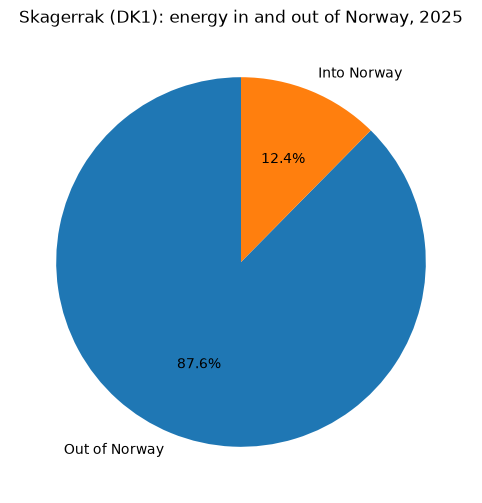

direction
export    8157016.0
import    1153573.0
Name: flow_mw, dtype: float64


In [17]:
PIE_CONNECTION = "Skagerrak (DK1)"
PIE_YEAR = 2025

# Keep the rows for the chosen connection and year.
year_data = extracted[
    (extracted["connection"] == PIE_CONNECTION)
    & (extracted["timestamp"].dt.year == PIE_YEAR)
]

# One total per direction.
totals = year_data.groupby("direction")["flow_mw"].sum()

# Rename the directions to something readable in the chart.
labels = {"export": "Out of Norway", "import": "Into Norway"}

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(totals, labels=[labels[d] for d in totals.index], autopct="%1.1f%%", startangle=90)
ax.set_title(f"{PIE_CONNECTION}: energy in and out of Norway, {PIE_YEAR}")
plt.show()

print(totals.round(0))

### Line plot: the first month of a year

One line per combination of connection and direction, for January of the chosen
year.

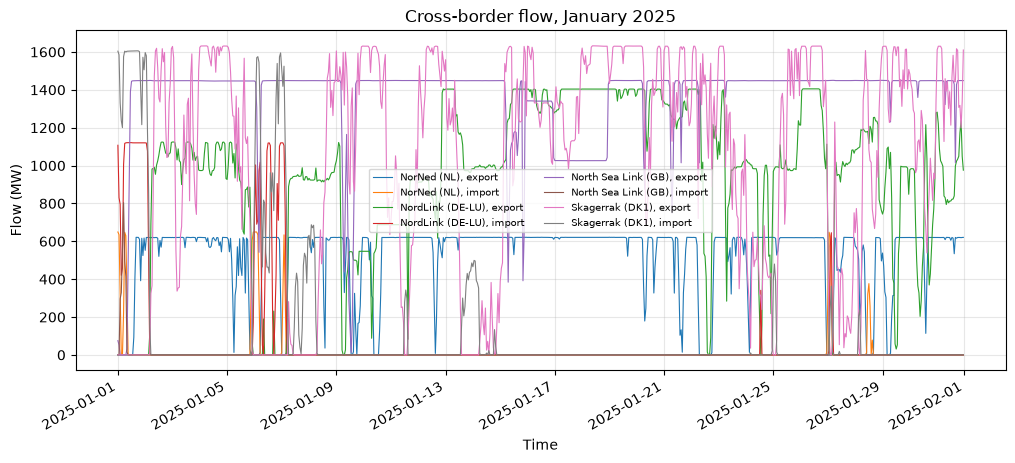

In [18]:
LINE_YEAR = 2025

# Keep January of the chosen year.
first_month = extracted[
    (extracted["timestamp"].dt.year == LINE_YEAR)
    & (extracted["timestamp"].dt.month == 1)
]

fig, ax = plt.subplots(figsize=(12, 5))

# Two lines per connection: one for each direction.
for connection in sorted(first_month["connection"].unique()):
    for direction in ["export", "import"]:
        series = first_month[
            (first_month["connection"] == connection)
            & (first_month["direction"] == direction)
        ].sort_values("timestamp")

        ax.plot(series["timestamp"], series["flow_mw"], linewidth=0.8,
                label=f"{connection}, {direction}")

ax.set_title(f"Cross-border flow, January {LINE_YEAR}")
ax.set_xlabel("Time")
ax.set_ylabel("Flow (MW)")
ax.grid(alpha=0.3)
ax.legend(fontsize=7, ncol=2)
fig.autofmt_xdate()
plt.show()

## 9. Insert into MongoDB

MongoDB is the database the Streamlit app reads from, since the app cannot reach
the local Cassandra instance. The data written here is the same data that was
extracted from Cassandra with Spark above.

In [19]:
database = mongo_client["ind320"]
collection = database["crossborder_flows"]

# Emptied first so the notebook can be run again without creating duplicates.
collection.delete_many({})

# MongoDB stores documents, which are dictionaries. to_dict("records") turns
# each row of the DataFrame into one dictionary.
collection.insert_many(extracted.to_dict("records"))

print("Documents in collection:", collection.count_documents({}))

Documents in collection: 140144


## 10. Log

*300 to 500 words about the work, covering both the Jupyter Notebook and the
Streamlit experience. To be written.*

## 11. AI declaration

*To be written.*